## Imports


In [1]:
from pathlib import Path
from collections import Counter
import gzip
import hashlib
import json
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.special import softmax
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import normalize
from sklearn.svm import LinearSVC
from threadpoolctl import threadpool_limits

## Configuration


In [18]:
DATA_DIR = None
RANDOM_STATE = 42
GRAINE_CONFIRMATION = 137
N_SPLITS = 4
VALEURS_C = [3.0, 5.0, 10.0, 20.0, 50.0]
POIDS_SVM = [0.85, 0.90, 0.95, 1.0]
MODES = ['log', 'contexte_rythme']
GENERER_SOUMISSION = True
FAMILLES = ['contextes', 'actions', 'sequences', 'parcours']
POIDS_FAMILLES = [1.0, 1.0, 1.0, 0.5]
print('Le CSV est généré uniquement si GENERER_SOUMISSION = True.')

Le CSV est généré uniquement si GENERER_SOUMISSION = True.


## Fichiers locaux ou Kaggle


In [3]:
def trouver_fichier(dossier, nom):
    for attendu in [nom.lower(), nom.lower() + '.gz']:
        correspondances = [p for p in Path(dossier).iterdir()
                          if p.is_file() and p.name.lower() == attendu]
        if len(correspondances) == 1:
            return correspondances[0]
        if len(correspondances) > 1:
            raise ValueError(f'Plusieurs fichiers {attendu} dans {dossier}')
    raise ValueError(f'Fichier {nom} ou {nom}.gz absent dans {dossier}')

if DATA_DIR is None:
    locaux = [p / 'data' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir()]
    candidats = []
    if Path('/kaggle/input').exists():
        candidats = sorted({p.parent for p in Path('/kaggle/input').rglob('*')
                            if p.is_file() and p.name.lower() in ('train.csv', 'train.csv.gz')})
    else:
        candidats = locaux
    candidats_valides = []
    for dossier in candidats:
        try:
            for nom in ['train.csv', 'test.csv', 'sample_submission.csv']:
                trouver_fichier(dossier, nom)
            candidats_valides.append(dossier)
        except ValueError:
            pass
    if len(candidats_valides) != 1:
        raise ValueError('Renseigner DATA_DIR : aucun dossier unique de compétition trouvé.')
    DATA_DIR = candidats_valides[0]
DATA_DIR = Path(DATA_DIR)
FICHIER_TRAIN = trouver_fichier(DATA_DIR, 'train.csv')
FICHIER_TEST = trouver_fichier(DATA_DIR, 'test.csv')
FICHIER_EXEMPLE = trouver_fichier(DATA_DIR, 'sample_submission.csv')
SORTIE = (Path('/kaggle/working') if Path('/kaggle/working').exists()
          else DATA_DIR.parent / 'datamanip') / 'resultats_008'
SORTIE.mkdir(parents=True, exist_ok=True)
print(DATA_DIR)

c:\Users\Rog strix Scar\Desktop\BE_MachineLearning\data


## Chargement


In [4]:
def ouvrir(path):
    with path.open('rb') as fichier:
        compresse = fichier.read(2) == b'\x1f\x8b'
    return (gzip.open(path, 'rt', encoding='utf-8-sig')
            if compresse else path.open(encoding='utf-8-sig'))

def charger(path, etiquete):
    lignes = []
    with ouvrir(path) as fichier:
        for ligne in fichier:
            champs = ligne.rstrip('\r\n').split(',')
            assert len(champs) >= (2 if etiquete else 1)
            lignes.append({'util': champs[0] if etiquete else None,
                           'navigateur': champs[1] if etiquete else champs[0],
                           'traces': champs[2:] if etiquete else champs[1:]})
    return pd.DataFrame(lignes)

train_df = charger(FICHIER_TRAIN, True)
test_df = charger(FICHIER_TEST, False)
with ouvrir(FICHIER_EXEMPLE) as fichier:
    exemple = pd.read_csv(fichier)
assert list(exemple.columns) == ['RowId', 'prediction']
assert len(exemple) == len(test_df)
assert np.array_equal(exemple.RowId, np.arange(1, len(test_df) + 1))
assert train_df.util.notna().all()
assert train_df.util.value_counts().min() >= N_SPLITS
print({'train': len(train_df), 'test': len(test_df),
       'utilisateurs': train_df.util.nunique(), 'plis': N_SPLITS})

{'train': 3279, 'test': 324, 'utilisateurs': 247, 'plis': 4}


## Préparation


In [5]:
def est_temps(trace):
    return re.fullmatch('t\\d+', trace) is not None

def type_action(action):
    nom = re.split('[(<$]', action, maxsplit=1)[0].strip()
    return nom[:-1].rstrip() if nom.endswith('1') else nom

def contextes(actions, motif):
    return [valeur for action in actions for valeur in re.findall(motif, action)]

def ajouter_comptages(cible, prefixe, valeurs):
    for valeur, nombre in Counter(valeurs).items():
        cible[prefixe + json.dumps(valeur, ensure_ascii=False)] = nombre

def ngrammes(valeurs, taille):
    return zip(*(valeurs[j:] for j in range(taille)))

df = pd.concat([train_df, test_df], ignore_index=True)
df['actions'] = df.traces.map(lambda traces: [t for t in traces if not est_temps(t)])
df['nb_actions'] = df.actions.map(len)
y = train_df.util.to_numpy()
classes = np.unique(y)
navigateurs = df.navigateur.to_numpy()
indices_train = np.arange(len(train_df))
indices_test = np.arange(len(train_df), len(df))
empreintes = df.traces.map(lambda t: hashlib.sha256(
    json.dumps(t, ensure_ascii=False).encode()).hexdigest())
print({'traces_identiques_train': int(empreintes.iloc[:len(train_df)].duplicated().sum()),
       'sessions_sans_action': int((df.nb_actions.iloc[:len(train_df)] == 0).sum())})

{'traces_identiques_train': 0, 'sessions_sans_action': 1}


## Variables de référence


In [6]:
def caracteristiques_reference(ligne):
    actions = ligne['actions']
    verbes = [type_action(a) for a in actions]
    temps = [int(t[1:]) for t in ligne['traces'] if est_temps(t)]
    ecrans = contextes(actions, '\\((.*?)\\)')
    configs = contextes(actions, '<(.*?)>')
    chaines = contextes(actions, '\\$(.*?)\\$')
    n = len(actions)
    modifications = sum((a.endswith('1') for a in actions))
    resultat = dict(nb_actions=n, nb_marqueurs_temporels=len(temps), dernier_repere_s=max(temps, default=0), sans_actions=int(n == 0), sans_marqueur_temporel=int(not temps), nb_actions_modification=modifications, part_actions_modification=modifications / n if n else 0, nb_types_actions_distincts=len(set(verbes)), nb_ecrans_contextes_distincts=len(set(ecrans)), nb_configurations_distinctes=len(set(configs)), nb_chaines_distinctes=len(set(chaines)), navigateur=ligne['navigateur'])
    for prefixe, valeurs in [('action_nombre', verbes), ('ecran_nombre', ecrans), ('configuration_nombre', configs), ('chaine_nombre', chaines)]:
        for valeur, nombre in Counter(valeurs).items():
            resultat[f'{prefixe}::{valeur}'] = nombre
    for valeur, nombre in Counter(verbes).items():
        resultat[f'action_proportion::{valeur}'] = nombre / n
    return resultat

def representations(actions, navigateur):
    verbes = [type_action(a) for a in actions]
    ecrans = contextes(actions, '\\((.*?)\\)')
    configurations = contextes(actions, '<(.*?)>')
    chaines = contextes(actions, '\\$(.*?)\\$')
    contexte = {'navigateur': navigateur}
    for prefixe, valeurs in [('action_nombre', verbes), ('ecran_nombre', ecrans), ('configuration_nombre', configurations), ('chaine_nombre', chaines)]:
        for valeur, nombre in Counter(valeurs).items():
            contexte[f'{prefixe}::{valeur}'] = nombre
    complet, sequences, parcours = ({}, {}, {})
    ajouter_comptages(complet, 'complete::', actions)
    for taille in (2, 3):
        ajouter_comptages(sequences, f'complete{taille}::', ngrammes(actions, taille))
        ajouter_comptages(parcours, f'verbe{taille}::', ngrammes(verbes, taille))
    ajouter_comptages(parcours, 'transition::', ngrammes(ecrans, 2))
    return {'historique': {**contexte, **complet, **sequences, **parcours}, 'contextes': contexte, 'actions': complet, 'sequences': sequences, 'parcours': parcours}

X_reference = [caracteristiques_reference(r) for r in df.to_dict('records')]
REPRESENTATIONS = [representations(a, n) for a, n in zip(df.actions, navigateurs)]

## Signatures contextuelles et rythme


In [7]:
def variables_supplementaires(ligne):
    actions = ligne['actions']
    signatures = {}
    for action in actions:
        ecrans = re.findall(r'\((.*?)\)', action)
        configs = re.findall(r'<(.*?)>', action)
        chaines = re.findall(r'\$(.*?)\$', action)
        ecran = ecrans[0] if ecrans else ''
        config = configs[0] if configs else ''
        chaine = chaines[0] if chaines else ''
        if ecran or config or chaine:
            ajouter_comptages(signatures, 'contexte::', [(ecran, config, chaine)])
            ajouter_comptages(signatures, 'action_contexte::',
                              [(type_action(action), ecran, config, chaine)])
    verbes = [type_action(a) for a in actions]
    repetitions, precedent, longueur = [], None, 0
    for verbe in verbes:
        if verbe == precedent:
            longueur += 1
        else:
            if longueur:
                repetitions.append(longueur)
            precedent, longueur = verbe, 1
    if longueur:
        repetitions.append(longueur)
    blocs, intervalles = [], []
    compte, dernier = 0, 0
    for trace in ligne['traces']:
        if est_temps(trace):
            temps = int(trace[1:])
            blocs.append(compte)
            intervalles.append(max(temps - dernier, 0))
            dernier, compte = temps, 0
        else:
            compte += 1
    if compte:
        blocs.append(compte)
    def statistiques(valeurs, prefixe):
        a = np.asarray(valeurs if valeurs else [0], dtype=float)
        return {prefixe + '_moyenne': float(a.mean()),
                prefixe + '_ecart_type': float(a.std()),
                prefixe + '_maximum': float(a.max())}
    rythme = {**statistiques(blocs, 'actions_par_fenetre'),
              **statistiques(intervalles, 'intervalle'),
              **statistiques(repetitions, 'repetitions'),
              'actions_par_seconde': len(actions) / max(dernier, 1),
              'fraction_repetitions': sum(max(r - 1, 0) for r in repetitions) / max(len(actions), 1),
              'sans_temps': float(not intervalles)}
    return signatures, rythme

SIGNATURES, RYTHMES = zip(*(variables_supplementaires(r) for r in df.to_dict('records')))

## Encodage appris dans chaque pli


In [8]:
def encoder(train, evaluation, mode):
    assert set(train).isdisjoint(evaluation)
    blocs_train, blocs_eval = [], []
    familles = [([r[f] for r in REPRESENTATIONS], p)
                for f, p in zip(FAMILLES, POIDS_FAMILLES)]
    if mode == 'contexte_rythme':
        familles.append((SIGNATURES, 0.5))
    for valeurs, poids in familles:
        vecteur = DictVectorizer(dtype=np.float32)
        a = vecteur.fit_transform([valeurs[i] for i in train])
        b = vecteur.transform([valeurs[i] for i in evaluation])
        garder = np.asarray((a != 0).sum(axis=0)).ravel() >= 2
        if not garder.any():
            continue
        tfidf = TfidfTransformer(sublinear_tf=True)
        blocs_train.append(poids * tfidf.fit_transform(a[:, garder]))
        blocs_eval.append(poids * tfidf.transform(b[:, garder]))
    if mode == 'contexte_rythme':
        vecteur = DictVectorizer(dtype=np.float32)
        a = vecteur.fit_transform([RYTHMES[i] for i in train])
        b = vecteur.transform([RYTHMES[i] for i in evaluation])
        a.data = np.log1p(a.data)
        b.data = np.log1p(b.data)
        blocs_train.append(0.25 * normalize(a))
        blocs_eval.append(0.25 * normalize(b))
    return (normalize(sparse.hstack(blocs_train, format='csr')),
            normalize(sparse.hstack(blocs_eval, format='csr')))

## Modèles


In [9]:
def filtrer_navigateur(scores, train, evaluation):
    resultat = scores.copy()
    for navigateur in np.unique(navigateurs[evaluation]):
        autorises = np.unique(y[train[navigateurs[train] == navigateur]])
        if len(autorises):
            positions = np.flatnonzero(navigateurs[evaluation] == navigateur)
            interdits = np.flatnonzero(~np.isin(classes, autorises))
            resultat[np.ix_(positions, interdits)] = 0
    return resultat / np.maximum(resultat.sum(axis=1, keepdims=True), 1e-30)

def predire_arbres(train, evaluation):
    resultat = np.zeros((len(evaluation), len(classes)), dtype=np.float32)
    for navigateur in np.unique(navigateurs[evaluation]):
        tr = train[navigateurs[train] == navigateur]
        positions = np.flatnonzero(navigateurs[evaluation] == navigateur)
        ev = evaluation[positions]
        specialise = len(tr) > 0
        if not specialise:
            tr = train
        if len(np.unique(y[tr])) == 1:
            resultat[positions, np.searchsorted(classes, y[tr[0]])] = 1
            continue

        def lignes(indices):
            return [{k: v for k, v in X_reference[i].items() if not (specialise and k == 'navigateur')} for i in indices]
        vecteur = DictVectorizer(dtype=np.float32)
        a = vecteur.fit_transform(lignes(tr))
        b = vecteur.transform(lignes(ev))
        modele = ExtraTreesClassifier(n_estimators=200, max_features=0.5, class_weight='balanced', n_jobs=2, random_state=RANDOM_STATE)
        with threadpool_limits(limits=2):
            modele.fit(a, y[tr])
            proba = modele.predict_proba(b)
        resultat[np.ix_(positions, np.searchsorted(classes, modele.classes_))] = proba
    return resultat

def ajuster_svm(a, b, train, evaluation, c):
    modele = LinearSVC(C=c, dual=True, max_iter=30000, random_state=RANDOM_STATE)
    with warnings.catch_warnings(), threadpool_limits(limits=2):
        warnings.simplefilter('error', ConvergenceWarning)
        modele.fit(a, y[train], sample_weight=np.ones(len(train)))
        marges = modele.decision_function(b)
    scores = np.zeros((len(evaluation), len(classes)), dtype=np.float32)
    scores[:, np.searchsorted(classes, modele.classes_)] = softmax(3 * marges, axis=1)
    return filtrer_navigateur(scores, train, evaluation)

CONFIGS = {f'{mode}_C{c:g}': {'mode': mode, 'C': c}
           for mode in MODES for c in VALEURS_C}
NOM_BASE = 'reference_90_10'
assert 'log_C20' in CONFIGS

## Prédictions hors pli


In [10]:
def calculer_oof(configs, graine):
    predictions = {nom: np.zeros((len(y), len(classes)), dtype=np.float32)
                   for nom in [*configs, 'arbres']}
    numeros = np.full(len(y), -1)
    cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=graine)
    for pli, (train, evaluation) in enumerate(cv.split(indices_train, y)):
        numeros[evaluation] = pli
        predictions['arbres'][evaluation] = predire_arbres(train, evaluation)
        for mode in dict.fromkeys(c['mode'] for c in configs.values()):
            a, b = encoder(train, evaluation, mode)
            for nom, config in configs.items():
                if config['mode'] == mode:
                    predictions[nom][evaluation] = ajuster_svm(
                        a, b, train, evaluation, config['C'])
            del a, b
        print(f'Graine {graine} : pli {pli + 1}/{N_SPLITS}', flush=True)
    assert (numeros >= 0).all()
    for scores in predictions.values():
        assert np.isfinite(scores).all()
        assert np.allclose(scores.sum(axis=1), 1, atol=1e-5)
    return predictions, numeros

oof, plis = calculer_oof(CONFIGS, RANDOM_STATE)
np.savez_compressed(SORTIE / 'predictions_oof.npz', y=y, classes=classes, plis=plis, **oof)

Graine 42 : pli 1/4
Graine 42 : pli 2/4
Graine 42 : pli 3/4
Graine 42 : pli 4/4


## Comparaison des modèles et mélanges


In [11]:
def mesurer(scores, numeros, recette, nom):
    prediction = classes[scores.argmax(axis=1)]
    par_pli = [f1_score(y[numeros == p], prediction[numeros == p],
                       average='macro', zero_division=0) for p in np.unique(numeros)]
    return {'modele': nom, 'f1_macro_oof': f1_score(y, prediction, average='macro', zero_division=0),
            'moyenne_plis': np.mean(par_pli), 'ecart_type_plis': np.std(par_pli),
            'accuracy': accuracy_score(y, prediction),
            'erreurs': int(np.sum(y != prediction)), 'recette': recette}

def combiner(predictions, recette):
    return sum(poids * predictions[nom] for nom, poids in recette.items())

RECETTES = {NOM_BASE: {'log_C20': 0.9, 'arbres': 1 - 0.9}}
RECETTES['arbres_seuls'] = {'arbres': 1.0}
for nom in CONFIGS:
    for poids in POIDS_SVM:
        RECETTES[f'{nom}_svm{poids:.2f}'] = {nom: poids, 'arbres': 1 - poids}
classement = pd.DataFrame([mesurer(combiner(oof, r), plis, r, nom)
                          for nom, r in RECETTES.items()])
classement = classement.sort_values('f1_macro_oof', ascending=False, kind='stable')
print(classement.drop(columns='recette').head(15).to_string(index=False))

                     modele  f1_macro_oof  moyenne_plis  ecart_type_plis  accuracy  erreurs
            log_C20_svm0.95      0.968826      0.965537         0.009827  0.973163       88
            log_C50_svm0.95      0.968826      0.965537         0.009827  0.973163       88
contexte_rythme_C20_svm0.90      0.968754      0.966357         0.010619  0.972858       89
contexte_rythme_C50_svm0.90      0.968570      0.966148         0.009465  0.972553       90
            log_C10_svm0.95      0.968563      0.965476         0.010751  0.973163       88
contexte_rythme_C50_svm0.95      0.968543      0.965846         0.010571  0.972553       90
contexte_rythme_C20_svm0.95      0.968188      0.965400         0.010144  0.972248       91
contexte_rythme_C50_svm0.85      0.968175      0.965865         0.008951  0.972248       91
            reference_90_10      0.968053      0.965162         0.010443  0.973163       88
            log_C20_svm0.90      0.968053      0.965162         0.010443  0.9731

## Complémentarité des erreurs


In [12]:
reference = classes[combiner(oof, RECETTES[NOM_BASE]).argmax(axis=1)]
diagnostics = []
for nom in CONFIGS:
    prediction = classes[oof[nom].argmax(axis=1)]
    diagnostics.append({
        'modele': nom,
        'corrections_reference': int(np.sum((reference != y) & (prediction == y))),
        'regressions_reference': int(np.sum((reference == y) & (prediction != y))),
        'erreurs_communes': int(np.sum((reference != y) & (prediction != y)))
    })
complementarite = pd.DataFrame(diagnostics)
print(complementarite.to_string(index=False))
meilleurs = {}
for mode in MODES:
    noms = [nom for nom, c in CONFIGS.items() if c['mode'] == mode]
    meilleurs[mode] = max(noms, key=lambda nom: f1_score(
        y, classes[oof[nom].argmax(axis=1)], average='macro', zero_division=0))
if len(meilleurs) == 2:
    a, b = list(meilleurs.values())
    pa, pb = classes[oof[a].argmax(axis=1)], classes[oof[b].argmax(axis=1)]
    complementaires = np.any((pa == y) & (pb != y)) and np.any((pa != y) & (pb == y))
    if complementaires:
        ajouts = []
        for poids_b in [0.25, 0.5, 0.75]:
            for poids_arbres in [0.0, 0.1]:
                recette = {a: (1 - poids_arbres) * (1 - poids_b),
                           b: (1 - poids_arbres) * poids_b, 'arbres': poids_arbres}
                nom = f'double_svm_{poids_b:.2f}_arbres{poids_arbres:.2f}'
                RECETTES[nom] = recette
                ajouts.append(mesurer(combiner(oof, recette), plis, recette, nom))
        classement = pd.concat([classement, pd.DataFrame(ajouts)], ignore_index=True)
classement = classement.sort_values('f1_macro_oof', ascending=False, kind='stable')
nom_candidat = classement.iloc[0]['modele']
recette_candidate = RECETTES[nom_candidat]
classement.drop(columns='recette').to_csv(SORTIE / 'classement_cv.csv', index=False)
complementarite.to_csv(SORTIE / 'complementarite.csv', index=False)
print(classement.drop(columns='recette').head(10).to_string(index=False))

             modele  corrections_reference  regressions_reference  erreurs_communes
             log_C3                      5                     24                83
             log_C5                      6                     23                82
            log_C10                      7                     20                81
            log_C20                      7                     19                81
            log_C50                      7                     17                81
 contexte_rythme_C3                      9                     22                79
 contexte_rythme_C5                      8                     22                80
contexte_rythme_C10                      8                     21                80
contexte_rythme_C20                      8                     18                80
contexte_rythme_C50                      8                     18                80
                     modele  f1_macro_oof  moyenne_plis  ecart_type_plis  ac

## Stabilité sur une seconde répartition


In [13]:
noms_requis = {nom for recette in [RECETTES[NOM_BASE], recette_candidate]
               for nom, poids in recette.items() if nom != 'arbres' and poids > 0}
configs_confirmation = {nom: CONFIGS[nom] for nom in CONFIGS if nom in noms_requis}
oof_confirmation, plis_confirmation = calculer_oof(configs_confirmation, GRAINE_CONFIRMATION)
comparaison = []
for nom in dict.fromkeys([NOM_BASE, nom_candidat]):
    recette = {k: v for k, v in RECETTES[nom].items() if v > 0}
    for graine, predictions, numeros in [
        (RANDOM_STATE, oof, plis),
        (GRAINE_CONFIRMATION, oof_confirmation, plis_confirmation)
    ]:
        ligne = mesurer(combiner(predictions, recette), numeros, recette, nom)
        ligne['graine'] = graine
        comparaison.append(ligne)
stabilite = pd.DataFrame(comparaison)
print(stabilite.drop(columns='recette').to_string(index=False))
base_conf = stabilite[(stabilite.modele == NOM_BASE) &
                     (stabilite.graine == GRAINE_CONFIRMATION)].iloc[0].f1_macro_oof
candidat_conf = stabilite[(stabilite.modele == nom_candidat) &
                         (stabilite.graine == GRAINE_CONFIRMATION)].iloc[0].f1_macro_oof
nom_retenu = nom_candidat if candidat_conf > base_conf else NOM_BASE
recette_retenue = {k: v for k, v in RECETTES[nom_retenu].items() if v > 0}
stabilite.drop(columns='recette').to_csv(SORTIE / 'stabilite.csv', index=False)
print('Modèle retenu :', nom_retenu, recette_retenue)
print('La seconde graine mesure la stabilité sur les mêmes données ; elle ne constitue pas un test indépendant.')

Graine 137 : pli 1/4
Graine 137 : pli 2/4
Graine 137 : pli 3/4
Graine 137 : pli 4/4
                    modele  f1_macro_oof  moyenne_plis  ecart_type_plis  accuracy  erreurs  graine
           reference_90_10      0.968053      0.965162         0.010443  0.973163       88      42
           reference_90_10      0.970939      0.967018         0.007813  0.974687       83     137
double_svm_0.25_arbres0.10      0.968891      0.966365         0.009682  0.973163       88      42
double_svm_0.25_arbres0.10      0.971738      0.967761         0.006569  0.974992       82     137
Modèle retenu : double_svm_0.25_arbres0.10 {'log_C50': 0.675, 'contexte_rythme_C20': 0.225, 'arbres': 0.1}
La seconde graine mesure la stabilité sur les mêmes données ; elle ne constitue pas un test indépendant.


## Analyse des erreurs


In [14]:
prediction = classes[combiner(oof, recette_retenue).argmax(axis=1)]
scores = combiner(oof, recette_retenue)
tries = np.sort(scores, axis=1)
diagnostic = pd.DataFrame({
    'session_id': indices_train + 1, 'utilisateur_reel': y, 'prediction': prediction,
    'navigateur': navigateurs[:len(y)], 'nb_actions': df.nb_actions.iloc[:len(y)].to_numpy(),
    'pli': plis, 'correct': prediction == y, 'reference_correcte': reference == y,
    'ecart_scores_top2': tries[:, -1] - tries[:, -2]
})
diagnostic['longueur'] = pd.cut(diagnostic.nb_actions,
    bins=[-1, 0, 20, 100, 500, np.inf], labels=['0', '1-20', '21-100', '101-500', '>500'])
erreurs = diagnostic[~diagnostic.correct]
confusions = erreurs.groupby(['utilisateur_reel', 'prediction']).size().sort_values(ascending=False)
par_longueur = diagnostic.groupby('longueur', observed=False).agg(
    sessions=('correct', 'size'), taux_correct=('correct', 'mean'))
par_utilisateur = diagnostic.groupby('utilisateur_reel').agg(
    sessions=('correct', 'size'), taux_correct=('correct', 'mean')).sort_values('taux_correct')
print('Confusions les plus fréquentes :')
print(confusions.head(15).to_string())
print(par_longueur.to_string())
print(par_utilisateur.head(15).to_string())
diagnostic.to_csv(SORTIE / 'diagnostic_oof.csv', index=False)
erreurs.to_csv(SORTIE / 'erreurs_oof.csv', index=False)
confusions.rename('nombre').to_csv(SORTIE / 'confusions.csv')
par_longueur.to_csv(SORTIE / 'erreurs_par_longueur.csv')

Confusions les plus fréquentes :
utilisateur_reel  prediction
skm               slq           5
hll               guh           4
flj               skm           3
esu               lgd           2
lgd               esu           2
zok               lra           2
cuw               zyk           2
ald               fuy           2
akx               skm           1
                  oqa           1
eqo               fvc           1
dit               npo           1
dbi               sps           1
azx               guh           1
azn               wht           1
          sessions  taux_correct
longueur                        
0                1      0.000000
1-20             3      0.333333
21-100         438      0.931507
101-500       1563      0.969290
>500          1274      0.994505
                  sessions  taux_correct
utilisateur_reel                        
hll                      9      0.222222
jew                      4      0.500000
rmf                      6      0

## Visualisation


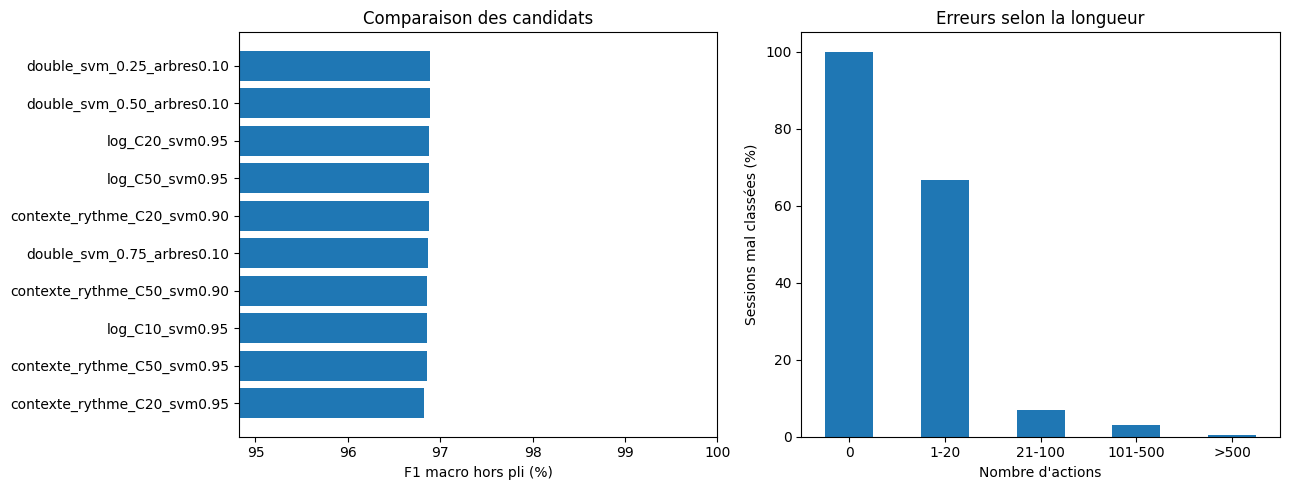

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top = classement.head(10).iloc[::-1]
axes[0].barh(top.modele, 100 * top.f1_macro_oof)
axes[0].set_xlabel('F1 macro hors pli (%)')
axes[0].set_title('Comparaison des candidats')
axes[0].set_xlim(max(0, 100 * top.f1_macro_oof.min() - 2), 100)
(100 * (1 - par_longueur.taux_correct)).plot.bar(ax=axes[1], rot=0)
axes[1].set_ylabel('Sessions mal classées (%)')
axes[1].set_xlabel("Nombre d'actions")
axes[1].set_title('Erreurs selon la longueur')
fig.tight_layout()
fig.savefig(SORTIE / 'comparaison.png', dpi=150, bbox_inches='tight')
plt.show()

## Recette retenue


In [16]:
resume = {
    'modele': nom_retenu, 'recette': recette_retenue,
    'configurations': {k: CONFIGS[k] for k in recette_retenue if k != 'arbres'},
    'graines': [RANDOM_STATE, GRAINE_CONFIRMATION], 'plis': N_SPLITS,
    'sha256_train_fichier': hashlib.sha256(FICHIER_TRAIN.read_bytes()).hexdigest(),
    'limite': 'Sélection sur validation croisée ; aucun nouveau score Kaggle mesuré.'
}
(SORTIE / 'recette.json').write_text(json.dumps(resume, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(resume, ensure_ascii=False, indent=2))

{
  "modele": "double_svm_0.25_arbres0.10",
  "recette": {
    "log_C50": 0.675,
    "contexte_rythme_C20": 0.225,
    "arbres": 0.1
  },
  "configurations": {
    "log_C50": {
      "mode": "log",
      "C": 50.0
    },
    "contexte_rythme_C20": {
      "mode": "contexte_rythme",
      "C": 20.0
    }
  },
  "graines": [
    42,
    137
  ],
  "plis": 4,
  "sha256_train_fichier": "4f806a85d36910a5a4dd8178fd465b34e6049a84e11f4ecb82f1c1b75e51e892",
  "limite": "Sélection sur validation croisée ; aucun nouveau score Kaggle mesuré."
}


## Entraînement final et CSV facultatif


In [19]:
if GENERER_SOUMISSION:
    predictions_finales = {}
    for nom, poids in recette_retenue.items():
        if nom == 'arbres':
            predictions_finales[nom] = predire_arbres(indices_train, indices_test)
        else:
            config = CONFIGS[nom]
            a, b = encoder(indices_train, indices_test, config['mode'])
            predictions_finales[nom] = ajuster_svm(a, b, indices_train, indices_test, config['C'])
    scores_test = combiner(predictions_finales, recette_retenue)
    assert np.isfinite(scores_test).all()
    assert np.allclose(scores_test.sum(axis=1), 1, atol=1e-5)
    soumission = exemple.copy()
    soumission['prediction'] = classes[scores_test.argmax(axis=1)]
    assert len(soumission) == len(test_df)
    assert not soumission.isna().any().any()
    assert soumission.prediction.isin(classes).all()
    chemin_csv = SORTIE / 'submission_008.csv'
    soumission.to_csv(chemin_csv, index=False)
    pd.testing.assert_frame_equal(pd.read_csv(chemin_csv), soumission)
    print(chemin_csv.resolve())
else:
    print('Aucun CSV généré. Passer GENERER_SOUMISSION à True puis exécuter cette cellule.')

C:\Users\Rog strix Scar\Desktop\BE_MachineLearning\datamanip\resultats_008\submission_008.csv
